<a href="https://colab.research.google.com/github/Ekimxii/fitness_pose_tracker/blob/main/coach_feedback.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Load Data

In [ ]:
!pip install -q -U fiftyone huggingface_hub Pillow

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.0/24.0 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.3/43.3 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.9/123.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.2/268.2 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 1.3 MB/s eta 0:00:00

In [ ]:
import fiftyone as fo
from fiftyone.utils.huggingface import load_from_hub
import pandas as pd

dataset_name = "Voxel51/qualcomm-exercise-video-dataset-benchmark"

if fo.dataset_exists(dataset_name):
    dataset = fo.load_dataset(dataset_name)
else:
    dataset = load_from_hub(dataset_name)

rows = []
for sample in dataset:
    for d in sample.feedback_events.detections:
        rows.append({
            "video_id": sample.video_id,
            "text": d.label,
            "start_frame": d.support[0],
            "end_frame": d.support[1],
            "type": d.feedback_type,
        })

df = pd.DataFrame(rows)
print(df.shape)
df.head(10)

INFO:fiftyone.utils.huggingface:Downloading config file fiftyone.yml from Voxel51/qualcomm-exercise-video-dataset-benchmark


Loading dataset


INFO:fiftyone.utils.huggingface:Loading dataset


Importing samples...


INFO:fiftyone.utils.data.importers:Importing samples...


...

INFO:eta.core.utils: 0 [4.3ms elapsed, ? remaining, ? samples/s]   


Migrating dataset 'Voxel51/qualcomm-exercise-video-dataset-benchmark' to v1.22.1


INFO:fiftyone.migrations.runner:Migrating dataset 'Voxel51/qualcomm-exercise-video-dataset-benchmark' to v1.22.1


(2511, 5)


,video_id,text,start_frame,end_frame,type
0,0006,Nice!,461,502,feedback
1,0006,Love the high knees!,503,567,feedback
2,0006,I really like the speed here. Keep it up!,574,638,feedback
3,0006,Awesome! Keep going!,664,727,feedback
4,0006,We're almost there with the high knees. Work i...,781,843,feedback
5,0006,That was really good! keep it up for the next ...,957,1021,feedback
6,0006,That's a good one!,1140,1203,feedback
7,0006,We are at 5 reps!,1204,1266,feedback
8,0006,10,1323,1382,feedback
9,0006,15,1428,1485,feedback


## Column Descriptions

**Granularity:** each row is one coaching feedback event (one message from the coach with its start and end frame) in one workout video. The dataset has 2511 rows from 74 videos.

| Column | Type | Description | Example |
|---|---|---|---|
| `video_id` | string | Identifier of the workout video session the message belongs to (74 unique). | `"0006"` |
| `text` | string | The coaching message: encouragement, rep counting, form corrections, or exercise announcement. | `"Love the high knees!"` |
| `start_frame` | integer | Video frame at which the message starts. Video is 30 FPS. | `461` |
| `end_frame` | integer | Video frame at which the message ends. | `502` |
| `type` | string | Event category from the source data: `transition` (announces a new exercise or the end of the session) or `feedback` (all other messages). | `"feedback"` |

## Data Cleaning

In [ ]:
rows,cols = df.shape # check numbers of rows and columns
print(f"Dataset has {rows} records and {cols} features")
print(df.info()) # check column types and non-null counts
print(df.isna().sum()) # check missing values per column
print(df["type"].value_counts()) # check which message types exist and how many of each

Dataset has 2511 records and 5 features
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2511 entries, 0 to 2510
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   video_id     2511 non-null   object
 1   text         2511 non-null   object
 2   start_frame  2511 non-null   int64 
 3   end_frame    2511 non-null   int64 
 4   type         2511 non-null   object
dtypes: int64(2), object(3)
memory usage: 98.2+ KB
None
video_id       0
text           0
start_frame    0
end_frame      0
type           0
dtype: int64
type
feedback      2013
transition     498
Name: count, dtype: int64


In [ ]:
df["text"] = df["text"].astype("string").str.strip() # ensure all the text is a string and remove leading or trailing spaces
empty = (df["text"] == "").sum() # count rows where text is missing
print("empty or missing text:",empty)
df = df[df["text"].notna() & (df["text"]!="")].copy() # keep only rows that have actual text

empty or missing text: 0


In [ ]:
# check if there are duplicated rows
before = len(df)
df = df.drop_duplicates(subset=["video_id","start_frame","end_frame","text"])
print("duplicate rows removed:",before - len(df))

duplicate rows removed: 0


In [ ]:
# check if all the messages are valid (start at frame 0 or later and end after it starts)
invalid_frames = (df["start_frame"]<0) | (df["end_frame"]<=df["start_frame"])
print("invalid frame:",invalid_frames.sum())

invalid frame: 0


In [ ]:
df = df.sort_values(["video_id","start_frame"]).reset_index(drop=True) # sort by video, then by time

In [ ]:
# Convert frames to seconds and measure message length, so the coach data is easier to interpret
# This is mainly for EDA and for setting coach parameters (e.g. how long a message should be and how often the coach speaks)
FPS = 30
df["start_s"] = df["start_frame"]/FPS
df["end_s"] = df["end_frame"]/FPS
df["duration_s"] = df["end_s"]-df["start_s"]
df["word_count"] = df["text"].str.split().str.len()

In [ ]:
print(df[["duration_s", "word_count"]].describe()) # print summary statistics to check if there are outliers

        duration_s   word_count
count  2511.000000  2511.000000
mean      2.088730     6.371963
std       0.333544     3.330804
min       0.333333     1.000000
25%       1.966667     5.000000
50%       2.100000     6.000000
75%       2.333333     8.000000
max       2.800000    33.000000


In [ ]:
df.head() # preview the cleaned table

,video_id,text,start_frame,end_frame,type,start_s,end_s,duration_s,word_count
0,0006,First up are high knees!,397,460,transition,13.233333,15.333333,2.100000,5
1,0006,Nice!,461,502,feedback,15.366667,16.733333,1.366667,1
2,0006,Love the high knees!,503,567,feedback,16.766667,18.900000,2.133333,4
3,0006,I really like the speed here. Keep it up!,574,638,feedback,19.133333,21.266667,2.133333,9
4,0006,Awesome! Keep going!,664,727,feedback,22.133333,24.233333,2.100000,3


## Data Visualization

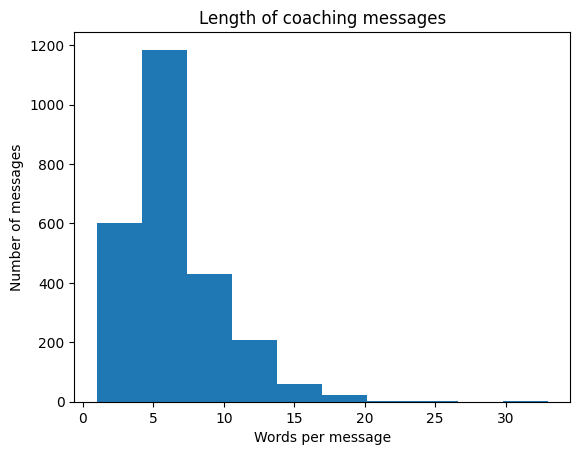

In [ ]:
# Visualization 1: histogram of message length
import matplotlib.pyplot as plt
plt.hist(df["word_count"])
plt.title("Length of coaching messages")
plt.xlabel("Words per message")
plt.ylabel("Number of messages")
plt.show()

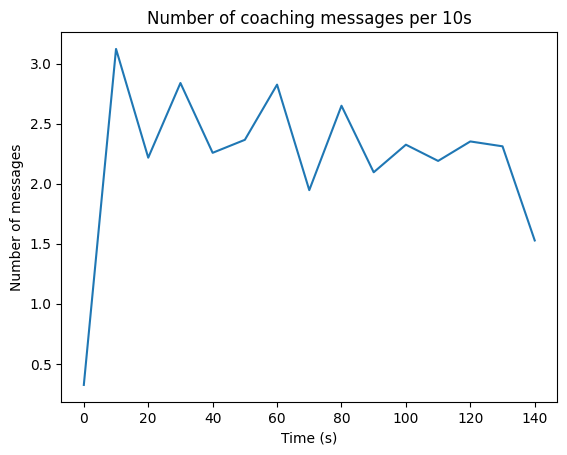

In [ ]:
# Visualization 2: line graph of how many messages the coach gives over time in a session
sub = df[df["start_s"] < 150].copy()  # keep the first 150 s, which every video covers
sub["time_bin"] = (sub["start_s"]//10*10).astype(int)
message_per_bin = sub.groupby("time_bin").size()/sub["video_id"].nunique()
plt.plot(message_per_bin.index,message_per_bin.values)
plt.title("Number of coaching messages per 10s")
plt.xlabel("Time (s)")
plt.ylabel("Number of messages")
plt.show()

## Feature Engineering

In [ ]:
!python -m spacy download en_core_web_sm

import re  # regular expressions, used to remove exercise names
import spacy  # NLP library: tokenizer, lemmatizer, part-of-speech tagger

nlp = spacy.load("en_core_web_sm")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 63.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Map word forms to standard body-part names

BODY_MAP = {
    "knee": "knee",
    "hip": "hip",
    "back": "back",
    "spine": "back",
    "chest": "chest",
    "shoulder": "shoulder",
    "core": "core",
    "ab": "core",
    "abs": "core",
    "stomach": "core",
    "belly": "core",
    "arm": "arm",
    "elbow": "elbow",
    "wrist": "wrist",
    "hand": "hand",
    "glute": "glute",
    "butt": "glute",
    "leg": "leg",
    "thigh": "thigh",
    "quad": "thigh",
    "hamstring": "thigh",
    "calf": "calf",
    "foot": "foot",
    "feet": "foot",
    "heel": "heel",
    "toe": "toe",
    "ankle": "ankle",
    "head": "head",
    "neck": "neck",
}


# 2. Exercise names that contain body-part words

EXERCISE_NAMES = [
    "high knees",
    "arm circles",
    "leg raises",
    "shoulder taps",
    "butt kickers",
    "quad stretch",
    "quad"
    "quad stretches",
    "arm cross chest",
]


# 3. Remove known exercise names from feedback text

def remove_exercise_names(text):
    text = str(text)

    for name in EXERCISE_NAMES:
        pattern = rf"\b{re.escape(name)}\b"

        text = re.sub(
            pattern,
            " ",
            text,
            flags=re.IGNORECASE
        )

    return text

In [ ]:
# 4. Extract standardized body parts from a spaCy Doc

def body_parts_in(doc):
    found = []

    for tok in doc:

        # Only consider nouns and proper nouns
        if tok.pos_ not in ("NOUN", "PROPN"):
            continue
        # Check the lemma first, then the original word
        for key in (tok.lemma_.lower(), tok.text.lower()):
            if key in BODY_MAP:
                part = BODY_MAP[key]
                # Keep each standard body part only once
                if part not in found:
                    found.append(part)
                break
    return found

# 6. Clean feedback messages and process them with spaCy
cleaned_texts = (
    df["text"]
    .fillna("")
    .astype(str)
    .map(remove_exercise_names)
)

docs = nlp.pipe(cleaned_texts, batch_size=128)

# 7. Create the new body_part column
body_part_results = []

for doc in docs:
    parts = body_parts_in(doc)

    if parts:
        body_part_results.append(", ".join(parts))
    else:
        body_part_results.append("none")

df["body_part"] = body_part_results



print("DataFrame shape:", df.shape)
print("\nBody-part counts:")
print(df["body_part"].value_counts().head(20))

print("\nSample results:")
print(df[["text", "body_part"]].head(20).to_string(index=False))

DataFrame shape: (2511, 7)

Body-part counts:
body_part
none           1907
arm              93
leg              82
shoulder         67
foot             52
toe              50
knee             49
core             18
elbow            18
back             17
thigh            17
hand             15
knee, chest      13
glute            11
chest             8
heel              6
arm, leg          6
hip               6
elbow, back       5
heel, glute       5
Name: count, dtype: int64

Sample results:
                                                                   text body_part
                                                                  Nice!      none
                                                   Love the high knees!      none
                              I really like the speed here. Keep it up!      none
                                                   Awesome! Keep going!      none
              We're almost there with the high knees. Work it, work it.      none
         

In [ ]:
df.head(30)

,video_id,text,start_frame,end_frame,type,mentions_body,body_part
0,0006,Nice!,461,502,feedback,False,none
1,0006,Love the high knees!,503,567,feedback,False,none
2,0006,I really like the speed here. Keep it up!,574,638,feedback,False,none
3,0006,Awesome! Keep going!,664,727,feedback,False,none
4,0006,We're almost there with the high knees. Work i...,781,843,feedback,False,none
5,0006,That was really good! keep it up for the next ...,957,1021,feedback,False,none
6,0006,That's a good one!,1140,1203,feedback,False,none
7,0006,We are at 5 reps!,1204,1266,feedback,False,none
8,0006,10,1323,1382,feedback,False,none
9,0006,15,1428,1485,feedback,False,none


##

In [ ]:
df.to_csv("qevd_feedback_text.csv", index=False) # for downloading as CSV file

from google.colab import files
files.download("qevd_feedback_text.csv")

# Sentiment



In [ ]:
# Install VADER (run this once per session)
!pip install vaderSentiment

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 2.6 MB/s eta 0:00:00


In [ ]:
# import VADER
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Tools we'll use
sia = SentimentIntensityAnalyzer()       # measures tone

# True for feedback rows, False for transition rows
mask = df["type"] == "feedback"

Tone (positive, negative, neutral)

In [ ]:
# Turn text into a tone label
def get_tone(text):
    score = sia.polarity_scores(str(text))["compound"]   # -1 to +1
    if score > 0.05:
        return "positive"
    elif score < -0.05:
        return "negative"
    return "neutral"

# Add the tone column (feedback rows only)
df["tone"] = None
df.loc[mask, "tone"] = df.loc[mask, "text"].apply(get_tone)

print(df[mask]["tone"].value_counts())

tone
positive    1036
neutral      903
negative      74
Name: count, dtype: int64


In [ ]:
# Phrases that signal praise or encouragement
compliment_cues = [
    "you got this", "crushed it", "great", "nice", "good", "awesome",
    "amazing", "well done", "keep it up", "keep this up", "keep'em coming",
    "keep them coming", "strong", "perfect", "that's it", "that's the correct",
    "better", "loving", "love", "yes!", "yeah!", "yup", "excellent", "beautiful"
]

# Phrases that signal a correction or adjustment
correction_cues = [
    "higher", "lower", "straighten", "straight", "faster", "slower",
    "deeper", "harder", "wait", "waiting", "make sure", "don't", "try",
    "should", "need to", "watch", "wrong", "still not", "not moving",
    "remember", "focus", "next time", "you want to", "get those",
    "opposite", "instead", "but "
]

Detect Constructive Feedback

In [ ]:
# True if the text contains any phrase from the list
def has_cue(text, cues):
    text = str(text).lower()
    return any(cue in text for cue in cues)

df["is_compliment"] = None
df["is_correction"] = None
df.loc[mask, "is_compliment"] = df.loc[mask, "text"].apply(lambda t: has_cue(t, compliment_cues))
df.loc[mask, "is_correction"] = df.loc[mask, "text"].apply(lambda t: has_cue(t, correction_cues))

Final label and Results

In [ ]:
# Correction wins, then compliment, then everything else
def label(row):
    if row["is_correction"]:
        return "constructive"
    if row["is_compliment"]:
        return "compliment"
    return "other"

df["feedback_kind"] = None
df.loc[mask, "feedback_kind"] = df.loc[mask].apply(label, axis=1)

print(df[mask]["feedback_kind"].value_counts())
print(df[mask][["text", "tone", "feedback_kind"]].sample(15))
print(pd.crosstab(df[mask]["tone"], df[mask]["feedback_kind"]))

feedback_kind
other           713
compliment      672
constructive    628
Name: count, dtype: int64
                                                   text      tone  \
443             Are you sure that's the right exercise?  positive   
2091                    Moving on to quad stretch left!   neutral   
2029                    This speed is great, keep it up  positive   
319                     Come on! Get those legs moving!   neutral   
992   Come on, let's give that upper body some love ...  positive   
1169                             That's it! Keep it up!  positive   
980   That's it. Now, can you feel the pull in your ...   neutral   
1988                     Come on! Try and bend forward.   neutral   
40                         That is awesome! Keep it up!  positive   
2050                                           15 reps!   neutral   
1054            Remember, keep your knees pointed down.   neutral   
1528                                          Right on.   neutral   
127

In [ ]:
# forcing compliments to be positive

# Keep VADER's original tone for reference
df["vader_tone"] = df["tone"]

# Compliments can't be negative: force them to positive
fix = mask & (df["feedback_kind"] == "compliment") & (df["tone"] == "negative")
df.loc[fix, "tone"] = "positive"

# Check: the 6 should now be gone
print(pd.crosstab(df[mask]["tone"], df[mask]["feedback_kind"]))

fix2 = mask & (df["feedback_kind"] == "compliment") & (df["tone"] == "neutral")
df.loc[fix2, "tone"] = "positive"

feedback_kind  compliment  constructive  other
tone                                          
negative                0            45     23
neutral                 0           273    560
positive              672           310    130


Snippet of sentiment analysis added to [df] + Actual df table

In [ ]:
df[df["type"] == "feedback"][["text", "tone", "feedback_kind"]].head(20)

,text,tone,feedback_kind
0,Nice!,positive,compliment
1,Love the high knees!,positive,compliment
2,I really like the speed here. Keep it up!,positive,compliment
3,Awesome! Keep going!,positive,compliment
4,We're almost there with the high knees. Work i...,neutral,other
5,That was really good! keep it up for the next ...,positive,compliment
6,That's a good one!,positive,compliment
7,We are at 5 reps!,neutral,other
8,10,neutral,other
9,15,neutral,other


In [ ]:
# cleaned [df] table ready for preview
df = df.drop(columns=["constructive", "is_compliment", "is_correction"], errors="ignore")
df.head()

,video_id,text,start_frame,end_frame,type,tone,feedback_kind,vader_tone
0,0006,Nice!,461,502,feedback,positive,compliment,positive
1,0006,Love the high knees!,503,567,feedback,positive,compliment,positive
2,0006,I really like the speed here. Keep it up!,574,638,feedback,positive,compliment,positive
3,0006,Awesome! Keep going!,664,727,feedback,positive,compliment,positive
4,0006,We're almost there with the high knees. Work i...,781,843,feedback,neutral,other,neutral


In [ ]:
# Save the labeled table as a CSV file
df.to_csv("feedback_labeled.csv", index=False)

In [ ]:
df.to_csv("qevd_feedback_text.csv", index=False) # for downloading as CSV file

from google.colab import files
files.download("qevd_feedback_text.csv")